# SQLite Schema Diagrammer

In [ ]:
from __future__ import annotations
import sqlite3
from pathlib import Path
from contextlib import closing
from dataclasses import dataclass
from gvdot import Dot, InvocationException, ProcessException, Markup
from IPython.display import display, Markdown

# Images are saved to images/ if it exists.
import os; save_images = os.path.isdir("images")

# Check Graphviz install.
try:
    Dot().graph(layout="neato").edge("a","b").to_svg()
except (InvocationException, ProcessException) as ex:
    print(ex)
    print()
    print("Graphviz dot is not on PATH, the neato layout engine is not ")
    print("available, or dot is not configured to produce SVG.  Check the ")
    print("Graphviz installation.")
    print()
    raise RuntimeError() from None

# Ensure SQLite database exists
if not Path("registration.sqlite").is_file():
    print()
    print("Required SQLite database registration.sqlite not found.")
    print()
    raise RuntimeError()

## Schema Representation

We create a general-purpose SQLite schema diagrammer that depicts tables and
their columns along with foreign key references between the tables.  We
represent a schema as a dictionary of `Table` objects.  Tables have

* A dictionary of `Column` objects specifying a database column's name, type,
and nullability, as well as whether or not the column is part of the table's
primary key, and whether or not the column is part of a unique index.

* A list of `ForeignKey` objects which are references from the tables.  Foreign
keys include the from (referencing) and to (referenced) tables along with the
participating columns of each.  A SQLite foreign key may be specified with
implicit referenced columns, in which case the `to_cols` attribute will be
None.

`ForeignKey` has two methods:

* `mandatory()` which is True if and only if none of the referencing columns is
  nullable, and

* `identifying()` which is True if and only if all referencing columns are part
  of the referencing table's primary key.

SQLite uses case-insensitive name comparison for the ASCII portion of names.
Function `object_name(name)` maps all uppercase ASCII characters of `name` to
lowercase.  Schema dictionaries (table and column) use keys returned by
`object_name`.

In [ ]:
type Schema = dict[str,Table]

@dataclass
class Table:
    name       : str
    columns    : dict[str,Column]
    references : list[ForeignKey]

@dataclass
class Column:
    name     : str
    type     : str
    nullable : bool
    pk       : bool
    unique   : bool

@dataclass
class ForeignKey:
    from_table: Table
    to_table  : Table
    from_cols : tuple[Column,...]
    to_cols   : tuple[Column,...] | None

    def mandatory(self) -> bool:
        return not any(col.nullable for col in self.from_cols)

    def identifying(self) -> bool:
        return all(col.pk for col in self.from_cols)

def object_name(name: str) -> str:
    return name.translate(_ASCII_LOWER)

_ASCII_LOWER = str.maketrans(
    "ABCDEFGHIJKLMNOPQRSTUVWXYZ",
    "abcdefghijklmnopqrstuvwxyz",
)

## Schema Loading

Function `load_schema(connection)` returns a schema given a SQLite database
connection.

In [ ]:
from collections import UserDict


def load_schema(connection:sqlite3.Connection) -> Schema:

    def query(sql:str, **parameters) -> list[tuple]:
        with closing(connection.execute(sql, parameters)) as cursor:
            return cursor.fetchall()

    #
    # Populate the schema with tables from the database, without columns or
    # foreign keys yet.
    #

    schema:dict[str,Table] = {
        object_name(name): Table(name,{},[])
        for (name,) in query("""
            select name from sqlite_schema
            where type = 'table'""")
    }

    #
    # Load table columns.  unique_cols are table columns participating in a
    # unique index.  Primary keys that alias rowid can never be null, even if
    # they lack a "not null" declaration.
    #

    for table in schema.values():

        unique_cols = set((
            object_name(name)
            for (name,) in query("""
                select index_info.name
                from pragma_index_list(:table_name) index_list,
                     pragma_index_info(index_list.name) index_info
                where index_list."unique" = 1 and index_info.name is not null;
            """, table_name=table.name)
        ))

        rowid_pk = not query("""
            select 1
            from pragma_index_list(:table_name)
            where origin = 'pk'
        """, table_name=table.name)

        for name, type, notnull, pk in query(
                """select name, type, "notnull", pk
                   from pragma_table_xinfo(:table_name)
                   where hidden <> 1""",
                table_name=table.name):
            objname = object_name(name)
            table.columns[objname] = Column(
                name=name, type=type,
                nullable=not (notnull or pk and rowid_pk),
                pk=bool(pk), unique=(objname in unique_cols))

    #
    # Load foreign keys.  Because pragma_foreign_key_list yields one row for
    # every column of a foreign key reference, we must sort and use break
    # processing.
    #

    def columns_for(table:Table, names:list[str]) -> tuple[Column,...]:
        return tuple(table.columns[object_name(name)] for name in names)

    for table in schema.values():

        fk_id        = None
        fk_to_table  = ""
        fk_from_cols = []
        fk_to_cols   = []

        def complete_fk():
            nonlocal fk_from_cols, fk_to_cols
            to_table  = schema[object_name(fk_to_table)]
            from_cols = columns_for(table, fk_from_cols)
            to_cols   = (None if fk_to_cols[0] is None else
                         columns_for(to_table, fk_to_cols))
            table.references.append(
                ForeignKey(from_table=table, to_table=to_table,
                           from_cols=from_cols, to_cols=to_cols))
            fk_from_cols.clear()
            fk_to_cols.clear()

        for id, to_table, from_col, to_col in query("""
                select id, "table", "from", "to"
                from pragma_foreign_key_list(:table_name)
                order by id, seq""", table_name=table.name):
            if fk_id != id:
                if fk_id is not None:
                    complete_fk()
                fk_to_table = to_table
                fk_id = id
            fk_from_cols.append(from_col)
            fk_to_cols.append(to_col)

        if fk_id is not None:
            complete_fk()

    return schema

## Sample Database

The gvdot `examples/` directory includes a simplified university course
registration database named `registration.sqlite`.

In [ ]:
with closing(sqlite3.connect("file:registration.sqlite?mode=ro",
                             uri=True, autocommit=True)) as connection:
    registration_schema = load_schema(connection)


We can better understand the schema data by inspecting the `section` table from
that database.

In [ ]:
from pprint import pprint
pprint(registration_schema[object_name('section')],depth=3)

Table(name='section',
      columns={'class_id': Column(name='class_id',
                                  type='INTEGER',
                                  nullable=False,
                                  pk=True,
                                  unique=True),
               'lead_ta_id': Column(name='lead_ta_id',
                                    type='INTEGER',
                                    nullable=True,
                                    pk=False,
                                    unique=False),
               'section_id': Column(name='section_id',
                                    type='INTEGER',
                                    nullable=False,
                                    pk=True,
                                    unique=True)},
      references=[ForeignKey(from_table=...,
                             to_table=Table(name='assistant',
                                            columns={...},
                                            references=[...]

## Node Labels

Our diagram will be a directed graph where each database table is a node and
each foreign key is an edge.  Since we want to show the database columns of
each table as part of the node, Graphviz HTML labels are the best choice.

Each node label will be an HTML table with a row for the database table name
and rows for each database column.  Database column rows will have four cells:
tag, name, type, and nullability.  The tag will indicate if the column is part
of a primary key, a foreign key, or a unique index. 

We use `Markup` subclasses defined in module `gvdot.markup` to build the
Graphviz HTML.  

In [ ]:
from gvdot.markup import TR, TD, Font, HR, Bold
from gvdot.markup import Table as MarkupTable  # Avoid name conflict

def table_markup(table:Table) -> Markup:
    return Font(face="sans-serif").add(
        MarkupTable(cellspacing=0, cellborder=0, border=1,
                    bgcolor="#eaeaef").add(
            _title_row(table.name), HR(),
            *(_dbcol_row(table,col) for col in table.columns.values())))

def _title_row(name:str):
    return TR(TD(Font(Bold(name), point_size=13, color="#ec8"),
                 colspan=4, bgcolor="#544"))

def _dbcol_row(table:Table, col:Column):

    col_fk = any(col in fk.from_cols for fk in table.references)
    tag, tag_color = (("PK", "darkgreen") if col.pk else
                      ("FK", "webpurple") if col_fk else
                      ("U", "goldenrod") if col.unique else ("","black"))

    indicator = Bold("?") if col.nullable else ""

    return TR(TD(Bold(Font(tag, color=tag_color, point_size=8)), align="left"),
              TD(Font(col.name+" ", point_size=10), align="left"),
              TD(Font(col.type, point_size=8, color="#338"), align="left"),
              TD(Font(indicator, point_size=8, color="#338")))

The type and parameter hints of `gvdot.markup` made creating the above easy
and almost entirely error free &mdash; a very different experience than trying
to generate that HTML directly.

A more subtle point is that we didn't need to worry about escaping.  Table
names, column names, and types are injected into the HTML as part of the
generation, and `gvdot.markup` escapes them for us.

Let's see how a label for table `section` looks:

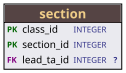

In [ ]:
dot = Dot().node_default(shape="plain")
dot.node(1, label=table_markup(registration_schema[object_name('section')]))
dot.show()

if save_images:
    dot.save("images/sqlite-node.svg")

## Theme

As mentioned earlier, we use edges to depict foreign keys.  Those edges must
communicate four things about a foreign key:

1. The referencing table,
2. The referenced table,
3. Whether or not the foreign key is identifying, and
4. Whether or not the foreign key is optional with respect to the child

We define a theme for our schema diagram to address all four with edge roles:

| Role Name | Style | Arrowhead | Assigned If |
| - | :-: | :-: | - |
| identifying    | solid   | &mdash; | fk.identifying() is True  |
| nonidentifying | dashed  | &mdash; | fk.identifying() is False |
| mandatory      | &mdash; | normal  | fk.mandatory() is True    |
| optional       | &mdash; | onormal | fk.mandatory() is False   |

Every edge will be assigned two roles: 
* one of "identifying" and "nonidentifying", and 
* one of "mandatory" and "optional".  

Because every edge will have an arrowhead, (1) and (2) will be addressed by
apparent directionality.  The visual distinction between "identifying" and
"nonidentifying" addresses (3).  Similarly, the orthogonal visual distinction
between "mandatory" and "optional" addresses (4).

The rest of the theme is straightforward.

In [ ]:
schema_theme = Dot()
schema_theme.graph(splines="true", layout="neato")
schema_theme.node_default(shape="plain")
schema_theme.edge_default(len=2.5, penwidth=2.0, color="#544")
schema_theme.edge_role("identifying", style="solid")
schema_theme.edge_role("nonidentifying", style="dashed")
schema_theme.edge_role("mandatory", arrowhead="normal")
schema_theme.edge_role("optional", arrowhead="onormal")
None

## Dot Object Generator

All that's left is the easiest part: writing the Dot object generator.

In [ ]:
def schema_diagram(schema:Schema) -> Dot:

    dot = Dot(directed=True).use_theme(schema_theme)

    for table in schema.values():
        dot.node(table.name, label=table_markup(table))

    for table in schema.values():
        for fk in table.references:
            to_table = fk.to_table
            dot.edge(table.name, to_table.name, role=(
                ("mandatory" if fk.mandatory() else "optional"),
                ("identifying" if fk.identifying() else "nonidentifying")))

    return dot

## Result

Let's see what the registration schema looks like.

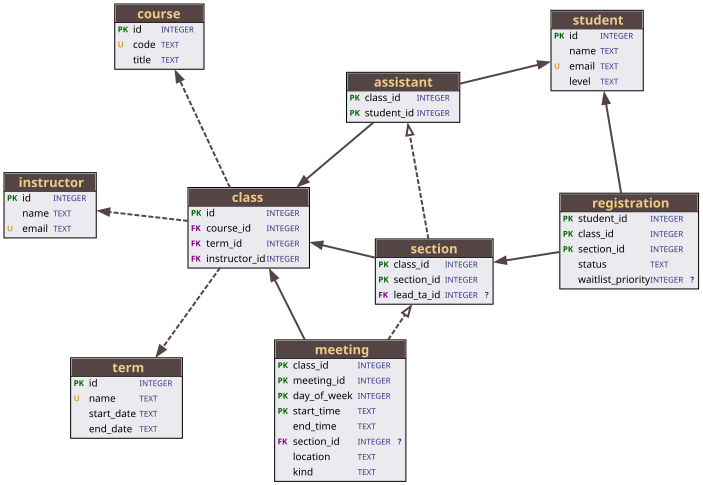

In [ ]:
diagram = schema_diagram(registration_schema)
diagram.show()

if save_images:
    diagram.save("images/sqlite-schema.svg")